In [4]:
from google.cloud import bigquery
import pandas as pd
import numpy as np
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

PROJECT = "fabled-ray-515710-e2"
client = bigquery.Client(project=PROJECT)

df = client.query(f"""
    select * from `{PROJECT}.thelook_dbt.dim_users`
""").to_dataframe()

print("All users:", df.shape)

# analysis population: 30-day window fully observed, no data-quality flag
elig = df[df.is_eligible_for_30d & ~df.has_order_before_signup]
print("Eligible users:", elig.shape)

print(elig.groupby("traffic_source").converted_30d.agg(["count", "sum", "mean"]).round(4))

/Users/ramisa/Projects/platform-api/thelook-analytics/venv/lib/python3.12/site-packages/google/auth/_default.py:113: UserWarning: Your application has authenticated using end user credentials from Google Cloud SDK without a quota project. You might receive a "quota exceeded" or "API not enabled" error. See the following page for troubleshooting: https://cloud.google.com/docs/authentication/adc-troubleshooting/user-creds. 
  warnings.warn(_CLOUD_SDK_CREDENTIALS_WARNING)
/Users/ramisa/Projects/platform-api/thelook-analytics/venv/lib/python3.12/site-packages/google/cloud/bigquery/table.py:2131: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


All users: (100000, 12)
Eligible users: (96414, 12)
                count   sum    mean
traffic_source                     
Display          3896   146  0.0375
Email            4662   193  0.0414
Facebook         5738   248  0.0432
Organic         14342   569  0.0397
Search          67776  2986  0.0441


In [5]:
a = elig[elig.traffic_source == "Search"].converted_30d.astype(int)
b = elig[elig.traffic_source == "Organic"].converted_30d.astype(int)

counts = [a.sum(), b.sum()]
nobs = [len(a), len(b)]

# test: H0 = both channels have the same conversion rate
z, p = proportions_ztest(counts, nobs)

# 95% confidence interval for the difference (Search minus Organic)
low, high = confint_proportions_2indep(counts[0], nobs[0], counts[1], nobs[1])

diff = a.mean() - b.mean()
print(f"Search : {a.mean():.4f}  ({counts[0]} of {nobs[0]})")
print(f"Organic: {b.mean():.4f}  ({counts[1]} of {nobs[1]})")
print(f"Difference: {diff:.4f} ({diff*100:.2f} percentage points)")
print(f"Relative lift: {diff / b.mean():.1%}")
print(f"95% CI for difference: [{low:.4f}, {high:.4f}]")
print(f"z = {z:.3f}, p-value = {p:.4f}")

Search : 0.0441  (2986 of 67776)
Organic: 0.0397  (569 of 14342)
Difference: 0.0044 (0.44 percentage points)
Relative lift: 11.0%
95% CI for difference: [0.0007, 0.0078]
z = 2.343, p-value = 0.0191


In [6]:
# order value among users who bought, same analysis population
buyers = elig[elig.order_count > 0]

x = buyers[buyers.traffic_source == "Search"].lifetime_revenue
y = buyers[buyers.traffic_source == "Organic"].lifetime_revenue

print(f"Buyers: Search {len(x)}, Organic {len(y)}")
print(f"Mean:   Search {x.mean():.2f}  Organic {y.mean():.2f}")
print(f"Median: Search {x.median():.2f}  Organic {y.median():.2f}")
print(f"Skewness: Search {stats.skew(x):.2f}  Organic {stats.skew(y):.2f}")

# Welch's t-test (does not assume equal variances)
t, p = stats.ttest_ind(x, y, equal_var=False)
diff = x.mean() - y.mean()
se = np.sqrt(x.var(ddof=1)/len(x) + y.var(ddof=1)/len(y))
print(f"\nWelch t-test: difference {diff:.2f}, "
      f"95% CI [{diff - 1.96*se:.2f}, {diff + 1.96*se:.2f}], t = {t:.3f}, p = {p:.4f}")

# non-parametric check, because revenue is usually right-skewed
u, p_mw = stats.mannwhitneyu(x, y, alternative="two-sided")
print(f"Mann-Whitney U: p = {p_mw:.4f}")

Buyers: Search 44904, Organic 9423
Mean:   Search 121.70  Organic 124.17
Median: Search 79.98  Organic 80.00
Skewness: Search 2.67  Organic 3.03

Welch t-test: difference -2.47, 95% CI [-5.38, 0.44], t = -1.664, p = 0.0961
Mann-Whitney U: p = 0.2960


Matplotlib is building the font cache; this may take a moment.
/Users/ramisa/Projects/platform-api/thelook-analytics/venv/lib/python3.12/site-packages/google/cloud/bigquery/table.py:2131: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


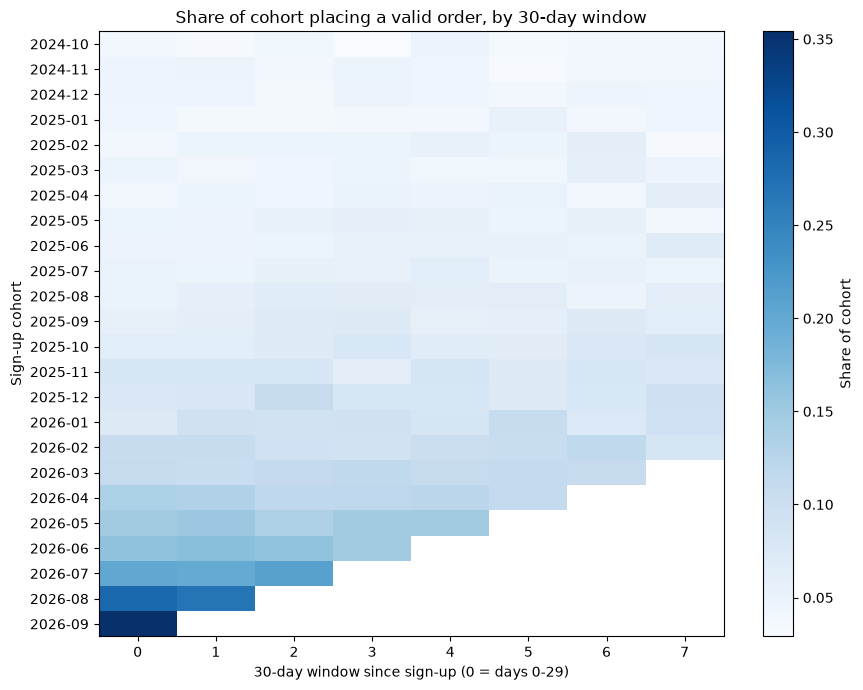

In [7]:
import matplotlib.pyplot as plt

ret = client.query(f"""
    select * from `{PROJECT}.thelook_dbt.mart_cohort_retention`
""").to_dataframe()

pivot = ret.pivot(index="cohort_month", columns="period_30d", values="retention_rate")
pivot = pivot.sort_index().iloc[-24:, :8]   # latest 24 cohorts, first 8 windows

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(pivot.values.astype(float), aspect="auto", cmap="Blues")
ax.set_xticks(range(pivot.shape[1]))
ax.set_xticklabels(pivot.columns)
ax.set_yticks(range(pivot.shape[0]))
ax.set_yticklabels([str(d)[:7] for d in pivot.index])
ax.set_xlabel("30-day window since sign-up (0 = days 0-29)")
ax.set_ylabel("Sign-up cohort")
ax.set_title("Share of cohort placing a valid order, by 30-day window")
fig.colorbar(im, label="Share of cohort")
plt.tight_layout()
plt.savefig("../images/cohort_heatmap.png", dpi=150)
plt.show()

# Methodology and findings

## Question
Do users from different acquisition channels differ in how often they buy, how much they spend, and how they return over time?

## Data and definitions
- **Source:** BigQuery public dataset `thelook_ecommerce` (synthetic), modelled with dbt into staging views and three mart tables.
- **Valid revenue:** order items that are not Cancelled or Returned.
- **Converted (30 days):** the user's first valid order falls within 30 days after sign-up.
- **Analysis population:** users who signed up at least 30 days ago (so the full window is observed) and who have no order dated before their sign-up (129 users excluded as a data-quality issue).
- **Cohort activity:** share of a sign-up-month cohort placing a valid order in each 30-day window after sign-up. A window appears only once every user in the cohort has been observed for all of it.

## Methods
- **Conversion rate, Search vs Organic:** two-proportion z-test with a 95% confidence interval for the difference.
- **Order value among buyers, Search vs Organic:** Welch's t-test (unequal variances) plus a Mann-Whitney test, because revenue is right-skewed (skewness about 2.7 to 3.0).

## Results
- **Conversion:** Search 4.41% vs Organic 3.97%. Difference 0.44 percentage points (11% relative), 95% CI [0.07, 0.78] percentage points, p = 0.019.
- **Order value:** Search 121.70 vs Organic 124.17 mean; medians 79.98 vs 80.00. Welch p = 0.096, Mann-Whitney p = 0.296. No evidence of a difference.
- **Takeaway:** Search converts slightly better, but its buyers spend about the same, so any advantage comes from more users buying, not larger orders.

## Caveats
1. **Small effect.** The conversion gap is statistically significant but small, and the confidence interval's lower end is close to zero.
2. **Multiple comparisons.** This was one pre-chosen comparison. Testing all 10 channel pairs would call for a correction (for example Bonferroni, 0.05/10 = 0.005), under which this result would not be significant.
3. **Observational data.** Users were not randomly assigned to channels, so the result shows association, not causation.
4. **Synthetic data.** Order activity per user rises over time (monthly orders grew from about 4,300 to 5,800 between July and October while sign-ups stayed flat), so cohorts are not like-for-like across months. Within-cohort patterns and channel comparisons are more reliable than cross-cohort trends.
5. **Lifetime revenue** depends on how long a user has existed, so older users have had more time to spend.
6. **Not shown:** Facebook, Email and Display were not tested, because Search vs Organic was chosen in advance as the main comparison.

## Data-quality finding
129 users (0.13%) had a first order dated before their sign-up, which is impossible in real data. They are flagged in `dim_users` (`has_order_before_signup`) and excluded from the analysis.